# Análisis exploratorio de satisfacción de pasajeros

## Objetivo

Identificar los factores relacionados con la satisfacción de los pasajeros y transformar los resultados en recomendaciones útiles para una aerolínea.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("../data/processed/airline_train_clean.csv")

## Pregunta 1: ¿Qué porcentaje de pasajeros está satisfecho?

In [ ]:
porcentaje_satisfaccion = (df["satisfaction"]
                           .value_counts(normalize=True).mul(100).round(2) )
porcentaje_satisfaccion

In [ ]:
plt.figure(figsize=(7, 7))

plt.pie(
    porcentaje_satisfaccion.values,
    labels=[
        "Neutral o\ninsatisfecho",
        "Satisfecho"
    ],
    autopct="%1.1f%%",
    labeldistance=0.52,
    pctdistance=0.78,
    textprops={
        "fontsize": 11,
        "fontweight": "bold"
    }
)

plt.title(
    "Distribución de la satisfacción de los pasajeros",
    fontweight="bold"
)

plt.show()

### Conclusión

El 43,34 % de los pasajeros se declaró satisfecho, mientras que el 56,66 % se encuentra en la categoría neutral o insatisfecha. Esto indica que menos de la mitad de los pasajeros manifiesta una experiencia claramente positiva y que existe una oportunidad importante de mejora.

## Pregunta 2: ¿Cómo cambia la satisfacción según la clase, el tipo de viaje y la fidelidad del cliente?

### Satisfacción según la clase

In [ ]:
satisfaccion_por_clase = pd.crosstab(
    df["class"],
    df["satisfaction"],
    normalize="index"
).mul(100).round(2)

satisfaccion_por_clase

In [ ]:
satisfaccion_por_clase_df = satisfaccion_por_clase.reset_index()
satisfaccion_por_clase_df

In [ ]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=satisfaccion_por_clase_df,
    x="class",
    y="satisfied"
)
ax.bar_label(
    ax.containers[0],
    fmt="%.2f%%"
)

ax.set_title("Satisfacción de los pasajeros por clase", fontweight="bold")
ax.set_xlabel("Clase")
ax.set_ylabel("Pasajeros satisfechos (%)")

ax.set_xticks(
    ax.get_xticks(),
    labels=["Business", "Eco", "Eco Plus"]
)

plt.tight_layout()
plt.show()

### Satisfacción según el tipo de viaje

In [ ]:
satisfaccion_por_viaje = pd.crosstab(
    df["type_of_travel"],
    df["satisfaction"],
    normalize="index"
).mul(100).round(2)

satisfaccion_por_viaje

In [ ]:
diferencia_viaje = round(58.26 - 10.16, 2)
diferencia_viaje

### Interpretación

Los pasajeros que viajan por negocios presentan un nivel de satisfacción del 58,26 %, mientras que entre quienes realizan viajes personales la satisfacción es del 10,16 %. Esto representa una diferencia de 48,10 puntos porcentuales.

Sin embargo, este resultado no demuestra que el motivo del viaje sea la causa directa de la diferencia. La clase del vuelo podría estar influyendo: si una mayor proporción de pasajeros de negocios viaja en Business, parte de su mayor satisfacción podría estar relacionada con las condiciones y los servicios de esa clase.

In [ ]:
satisfaccion_por_viaje_df = satisfaccion_por_viaje.reset_index()
satisfaccion_por_viaje_df.head()

In [ ]:
plt.figure(figsize=(8,5))
ax = sns.barplot(
    data=satisfaccion_por_viaje_df,
    x="type_of_travel",
    y="satisfied"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.2f%%"
)

ax.set_xticks(
    ax.get_xticks(),
    labels=["Negocios", "Personal"]
)

ax.set_title("Satisfacción de los pasajeros por tipo de viaje", fontweight="bold")
ax.set_xlabel("Tipo de viaje")
ax.set_ylabel("Pasajeros satisfechos (%)")

plt.tight_layout()
plt.show()

#### Análisis complementario: relación entre tipo de viaje y clase

In [ ]:
clase_por_tipo_viaje = pd.crosstab(
    df["type_of_travel"],
    df["class"],
    normalize="index"
).mul(100).round(2)

clase_por_tipo_viaje

La mayoría de los pasajeros que viajan por negocios lo hace en clase Business, mientras que la mayoría de quienes realizan viajes personales viaja en clase Eco. Esta diferencia podría explicar parte de la mayor satisfacción observada entre los pasajeros de negocios. Sin embargo, todavía debemos comparar ambos tipos de viaje dentro de una misma clase para determinar si el motivo del viaje también está relacionado con la satisfacción.

In [23]:
satisfaccion_viaje_clase = pd.crosstab(
    [df["type_of_travel"], df["class"]],
    df["satisfaction"],
    normalize="index"
).mul(100).round(2)

satisfaccion_viaje_clase

satisfaction              neutral or dissatisfied  satisfied
type_of_travel  class                                       
business travel business                    27.98      72.02
                eco                         70.38      29.62
                eco plus                    60.69      39.31
personal travel business                    87.72      12.28
                eco                         89.81      10.19
                eco plus                    91.33       8.67

### Conclusión del análisis complementario

La mayor satisfacción de los pasajeros de negocios se explica parcialmente porque una gran proporción viaja en clase Business. Sin embargo, la clase no explica toda la diferencia.

Al comparar pasajeros de la misma clase, quienes viajan por negocios continúan presentando una satisfacción considerablemente mayor. Dentro de Business, la satisfacción alcanza el 72,02 % en los viajes de negocios, pero solamente el 12,28 % en los viajes personales.

Además, entre los viajes personales la satisfacción se mantiene baja en todas las clases. Por lo tanto, tanto la clase como el motivo del viaje están asociados con la satisfacción, y la relación entre ambas variables debe analizarse de manera conjunta.

### Satisfacción según la fidelidad del cliente

satisfaccion_por_clase = pd.crosstab(
    df["class"],
    df["satisfaction"],
    normalize="index"
).mul(100).round(2)

satisfaccion_por_clase

In [ ]:
satisfaccion_por_fidelidad = pd.crosstab(
    df["customer_type"],
    df["satisfaction"],
    normalize="index"
).mul(100).round(2)

satisfaccion_por_fidelidad

In [ ]:
diferencia_fidelidad = round(47.73 - 23.68, 2)
diferencia_fidelidad

### Interpretación

Los clientes fieles presentan un 47,73 % de satisfacción, mientras que entre los clientes no fieles el porcentaje disminuye al 23,68 %. La diferencia es de 24,05 puntos porcentuales.

Esto muestra una asociación entre la fidelidad y la satisfacción, pero no permite determinar por sí solo qué provoca la diferencia. También podrían influir la clase del vuelo, el tipo de viaje, los beneficios recibidos y las valoraciones de servicios como el wifi, la comida o la comodidad del asiento.

In [ ]:
satisfaccion_por_fidelidad_df = satisfaccion_por_fidelidad.reset_index()
satisfaccion_por_fidelidad_df

In [ ]:
plt.figure(figsize=(8,5))
ax = sns.barplot(
    data=satisfaccion_por_fidelidad_df,
    x="customer_type",
    y="satisfied"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.2f%%"
)

ax.set_xticks(
    ax.get_xticks(),
    labels=["No Leal", "Leal"]
)

ax.set_title("Satisfacción de los pasajeros por fidelidad", fontweight="bold")
ax.set_xlabel("Nivel de Lealtad del pasajero")
ax.set_ylabel("Pasajeros satisfechos (%)")

plt.tight_layout()
plt.show()

## Pregunta 3: ¿Qué servicios están más relacionados con la satisfacción?

In [24]:
df["satisfaction_numeric"] = df["satisfaction"].map({
    "satisfied": 1,
    "neutral or dissatisfied": 0
})

In [25]:
df[["satisfaction", "satisfaction_numeric"]].head()

,satisfaction,satisfaction_numeric
0,neutral or dissatisfied,0
1,neutral or dissatisfied,0
2,satisfied,1
3,neutral or dissatisfied,0
4,satisfied,1


In [28]:
df.columns

Index(['gender', 'customer_type', 'age', 'type_of_travel', 'class',
       'flight_distance', 'inflight_wifi_service',
       'departure_arrival_time_convenient', 'ease_of_online_booking',
       'gate_location', 'food_and_drink', 'online_boarding', 'seat_comfort',
       'inflight_entertainment', 'on_board_service', 'leg_room_service',
       'baggage_handling', 'checkin_service', 'inflight_service',
       'cleanliness', 'departure_delay_in_minutes', 'arrival_delay_in_minutes',
       'satisfaction', 'satisfaction_numeric'],
      dtype='str')

In [30]:
columnas_servicios = [
    "inflight_wifi_service",
    "departure_arrival_time_convenient",
    "ease_of_online_booking",
    "gate_location", 
    "food_and_drink",
    "online_boarding",
    "seat_comfort",
    "inflight_entertainment",
    "on_board_service",
    "leg_room_service",
    "baggage_handling",
    "checkin_service",
    "inflight_service",
    "cleanliness"
]

In [32]:
variables_correlacion = columnas_servicios + ["satisfaction_numeric"]
variables_correlacion

['inflight_wifi_service',
 'departure_arrival_time_convenient',
 'ease_of_online_booking',
 'gate_location',
 'food_and_drink',
 'online_boarding',
 'seat_comfort',
 'inflight_entertainment',
 'on_board_service',
 'leg_room_service',
 'baggage_handling',
 'checkin_service',
 'inflight_service',
 'cleanliness',
 'satisfaction_numeric']

In [35]:
correlaciones_servicios = (
    df[variables_correlacion]
    .corr()
    .round(2)
)

ranking_servicios = (
    correlaciones_servicios["satisfaction_numeric"]
    .drop("satisfaction_numeric")
    .sort_values(ascending=False)
)

ranking_servicios

online_boarding                      0.50
inflight_entertainment               0.40
seat_comfort                         0.35
on_board_service                     0.32
leg_room_service                     0.31
cleanliness                          0.31
inflight_wifi_service                0.28
baggage_handling                     0.25
checkin_service                      0.24
inflight_service                     0.24
food_and_drink                       0.21
ease_of_online_booking               0.17
gate_location                        0.00
departure_arrival_time_convenient   -0.05
Name: satisfaction_numeric, dtype: float64

### Interpretación y recomendación

El embarque online presenta la relación más fuerte con la satisfacción (0,50), seguido por el entretenimiento a bordo (0,40) y la comodidad del asiento (0,35).

Sin embargo, la prioridad de mejora no debería definirse únicamente por la correlación. También deben considerarse el costo y la facilidad de implementación. Por este motivo, recomendaría priorizar:

1. **Embarque online:** simplificar el proceso, reducir errores y mejorar la experiencia digital.
2. **Entretenimiento a bordo:** ampliar o actualizar los contenidos y asegurar el correcto funcionamiento del sistema.
3. **Check-in y servicio durante el vuelo:** capacitar al personal y optimizar los procesos de atención.

La comodidad del asiento y el espacio para las piernas también están relacionados con la satisfacción, pero podrían requerir inversiones estructurales más costosas. Estas recomendaciones representan áreas para investigar y probar; las correlaciones no demuestran por sí solas una relación causal.

In [36]:
ranking_servicios_df = ranking_servicios.reset_index()
ranking_servicios_df

,index,satisfaction_numeric
0,online_boarding,0.50
1,inflight_entertainment,0.40
2,seat_comfort,0.35
3,on_board_service,0.32
4,leg_room_service,0.31
5,cleanliness,0.31
6,inflight_wifi_service,0.28
7,baggage_handling,0.25
8,checkin_service,0.24
9,inflight_service,0.24


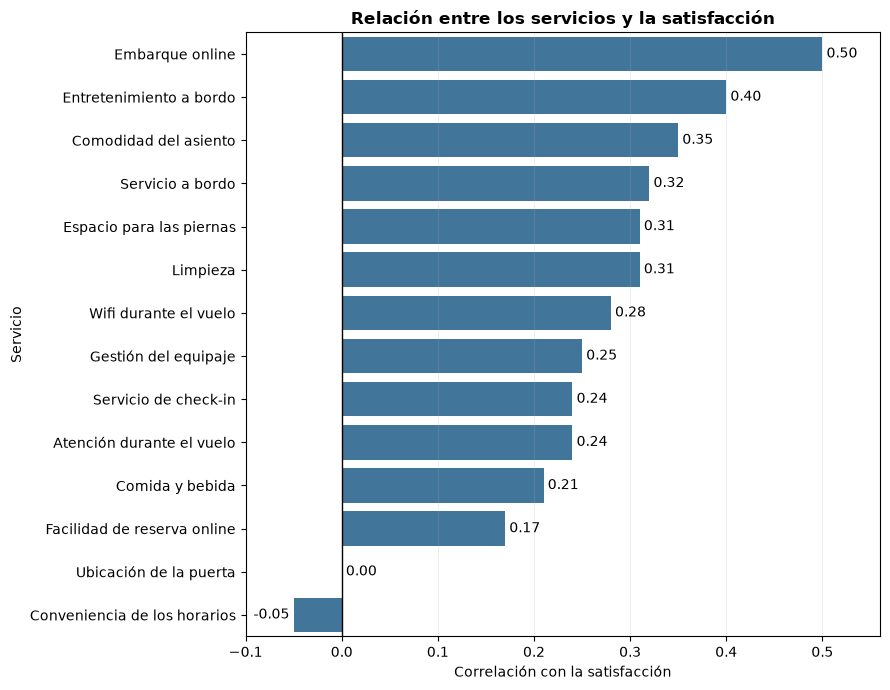

In [37]:
ranking_servicios_df.columns = [
    "servicio",
    "correlacion"
]  # Renombra las columnas para facilitar el gráfico

nombres_servicios = {
    "online_boarding": "Embarque online",
    "inflight_entertainment": "Entretenimiento a bordo",
    "seat_comfort": "Comodidad del asiento",
    "on_board_service": "Servicio a bordo",
    "leg_room_service": "Espacio para las piernas",
    "cleanliness": "Limpieza",
    "inflight_wifi_service": "Wifi durante el vuelo",
    "baggage_handling": "Gestión del equipaje",
    "checkin_service": "Servicio de check-in",
    "inflight_service": "Atención durante el vuelo",
    "food_and_drink": "Comida y bebida",
    "ease_of_online_booking": "Facilidad de reserva online",
    "gate_location": "Ubicación de la puerta",
    "departure_arrival_time_convenient": "Conveniencia de los horarios"
}

ranking_servicios_df["servicio"] = (
    ranking_servicios_df["servicio"]
    .replace(nombres_servicios)
)  # Reemplaza los nombres técnicos por nombres más claros

plt.figure(figsize=(9, 7))

ax = sns.barplot(
    data=ranking_servicios_df,
    x="correlacion",
    y="servicio",
    color="#3478A8"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.2f",
    padding=3
)

ax.axvline(
    x=0,
    color="black",
    linewidth=1
)

ax.set_title(
    "Relación entre los servicios y la satisfacción",
    fontweight="bold"
)

ax.set_xlabel("Correlación con la satisfacción")
ax.set_ylabel("Servicio")
ax.set_xlim(-0.10, 0.56)

plt.grid(axis="x", alpha=0.20)
plt.tight_layout()
plt.show()

## Pregunta 4: ¿Cómo afectan los retrasos a la satisfacción?

In [38]:
resumen_retrasos = (
    df
    .groupby("satisfaction")
    [["departure_delay_in_minutes", "arrival_delay_in_minutes"]]
    .agg(["mean", "median"])
    .round(2)
)

resumen_retrasos

departure_delay_in_minutes         \
                                              mean median   
satisfaction                                                
neutral or dissatisfied                      16.43    0.0   
satisfied                                    12.55    0.0   

                        arrival_delay_in_minutes         
                                            mean median  
satisfaction                                             
neutral or dissatisfied                    17.13    0.0  
satisfied                                  12.63    0.0

In [40]:
df["grupo_retraso_llegada"] = pd.cut(
    df["arrival_delay_in_minutes"],
    bins=[-1, 0, 15, 30, 60, float("inf")],
    labels=[
        "Sin retraso",
        "1-15 minutos",
        "16-30 minutos",
        "31-60 minutos",
        "Más de 60 minutos"
    ]
)
df["grupo_retraso_llegada"].value_counts(sort=False)

grupo_retraso_llegada
Sin retraso          58159
1-15 minutos         21800
16-30 minutos         8973
31-60 minutos         7335
Más de 60 minutos     7327
Name: count, dtype: int64

In [41]:
satisfaccion_por_retraso = pd.crosstab(
    df["grupo_retraso_llegada"],
    df["satisfaction"],
    normalize="index"
).mul(100).round(2)

satisfaccion_por_retraso

satisfaction,neutral or dissatisfied,satisfied
grupo_retraso_llegada,,
Sin retraso,52.72,47.28
1-15 minutos,58.70,41.30
16-30 minutos,64.73,35.27
31-60 minutos,64.36,35.64
Más de 60 minutos,64.28,35.72


In [42]:
diferencia_retraso = round(47.28 - 35.72, 2)
diferencia_retraso

11.56

### Interpretación y recomendación

Los pasajeros sin retraso presentan un 47,28 % de satisfacción, mientras que entre quienes sufren demoras superiores a 60 minutos la satisfacción disminuye al 35,72 %. Esto representa una diferencia de 11,56 puntos porcentuales.

La principal caída ocurre durante los primeros 30 minutos y, especialmente, al superar los 15 minutos. Después, la satisfacción se mantiene cerca del 35 %, incluso cuando el retraso aumenta.

Por lo tanto, la aerolínea debería priorizar la prevención de retrasos superiores a 15 minutos. Cuando la demora no pueda evitarse, debería mejorar la comunicación, la asistencia y la gestión de los pasajeros afectados. Los resultados muestran una asociación, pero no demuestran que el retraso sea la única causa de la insatisfacción.

In [43]:
satisfaccion_por_retraso_df = satisfaccion_por_retraso.reset_index()
satisfaccion_por_retraso_df

satisfaction,grupo_retraso_llegada,neutral or dissatisfied,satisfied
0,Sin retraso,52.72,47.28
1,1-15 minutos,58.70,41.30
2,16-30 minutos,64.73,35.27
3,31-60 minutos,64.36,35.64
4,Más de 60 minutos,64.28,35.72


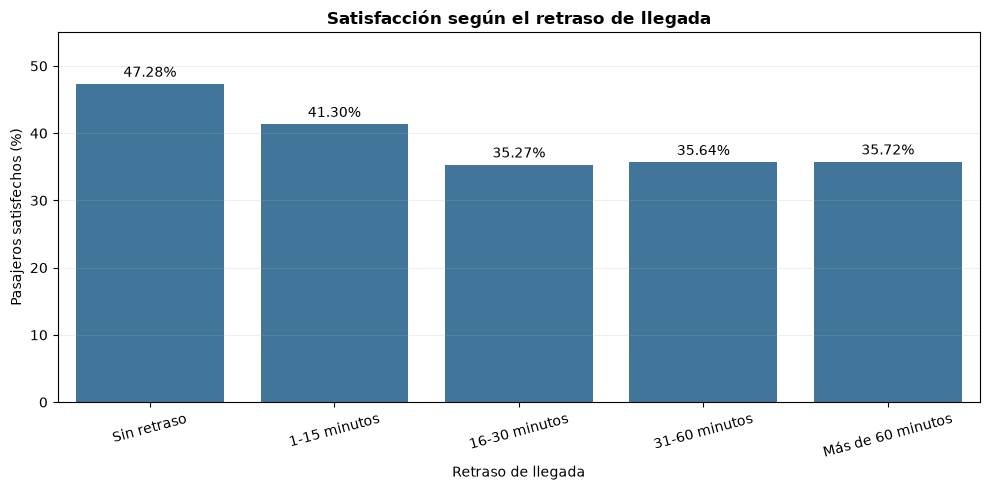

In [44]:
satisfaccion_por_retraso_df = (
    satisfaccion_por_retraso
    .reset_index()
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=satisfaccion_por_retraso_df,
    x="grupo_retraso_llegada",
    y="satisfied",
    color="#3478A8"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.2f%%",
    padding=3
)

ax.set_title(
    "Satisfacción según el retraso de llegada",
    fontweight="bold"
)

ax.set_xlabel("Retraso de llegada")
ax.set_ylabel("Pasajeros satisfechos (%)")
ax.set_ylim(0, 55)

plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.20)
plt.tight_layout()
plt.show()

## Pregunta 5: ¿Qué perfil de pasajero presenta mayor riesgo de insatisfacción?

In [45]:
perfiles_pasajeros = (
    df
    .groupby([
        "customer_type",
        "type_of_travel",
        "class"
    ])
    .agg(
        cantidad_pasajeros=("satisfaction_numeric", "size"),
        satisfaccion_promedio=("satisfaction_numeric", "mean")
    )
    .reset_index()
)

perfiles_pasajeros

,customer_type,type_of_travel,class,cantidad_pasajeros,satisfaccion_promedio
0,disloyal customer,business travel,business,7331,0.396126
1,disloyal customer,business travel,eco,10729,0.139715
2,disloyal customer,business travel,eco plus,709,0.078984
3,disloyal customer,personal travel,business,11,0.000000
4,disloyal customer,personal travel,eco,148,0.168919
5,disloyal customer,personal travel,eco plus,4,0.000000
6,loyal customer,business travel,business,40053,0.779517
7,loyal customer,business travel,eco,9473,0.473345
8,loyal customer,business travel,eco plus,3170,0.463407
9,loyal customer,personal travel,business,2138,0.123480


In [46]:
perfiles_confiables = (
    perfiles_pasajeros[
        perfiles_pasajeros["cantidad_pasajeros"] >= 500
    ]
    .copy()
)

In [47]:
perfiles_confiables["porcentaje_satisfechos"] = (
    perfiles_confiables["satisfaccion_promedio"]
    .mul(100)
    .round(2)
)

perfiles_confiables["porcentaje_no_satisfechos"] = (
    100 - perfiles_confiables["porcentaje_satisfechos"]
).round(2)

In [48]:
ranking_riesgo = (
    perfiles_confiables
    .sort_values(
        by="porcentaje_no_satisfechos",
        ascending=False
    )
)

ranking_riesgo

,customer_type,type_of_travel,class,cantidad_pasajeros,satisfaccion_promedio,porcentaje_satisfechos,porcentaje_no_satisfechos
2,disloyal customer,business travel,eco plus,709,0.078984,7.90,92.10
11,loyal customer,personal travel,eco plus,3585,0.086750,8.68,91.32
10,loyal customer,personal travel,eco,26243,0.101475,10.15,89.85
9,loyal customer,personal travel,business,2138,0.123480,12.35,87.65
1,disloyal customer,business travel,eco,10729,0.139715,13.97,86.03
0,disloyal customer,business travel,business,7331,0.396126,39.61,60.39
8,loyal customer,business travel,eco plus,3170,0.463407,46.34,53.66
7,loyal customer,business travel,eco,9473,0.473345,47.33,52.67
6,loyal customer,business travel,business,40053,0.779517,77.95,22.05


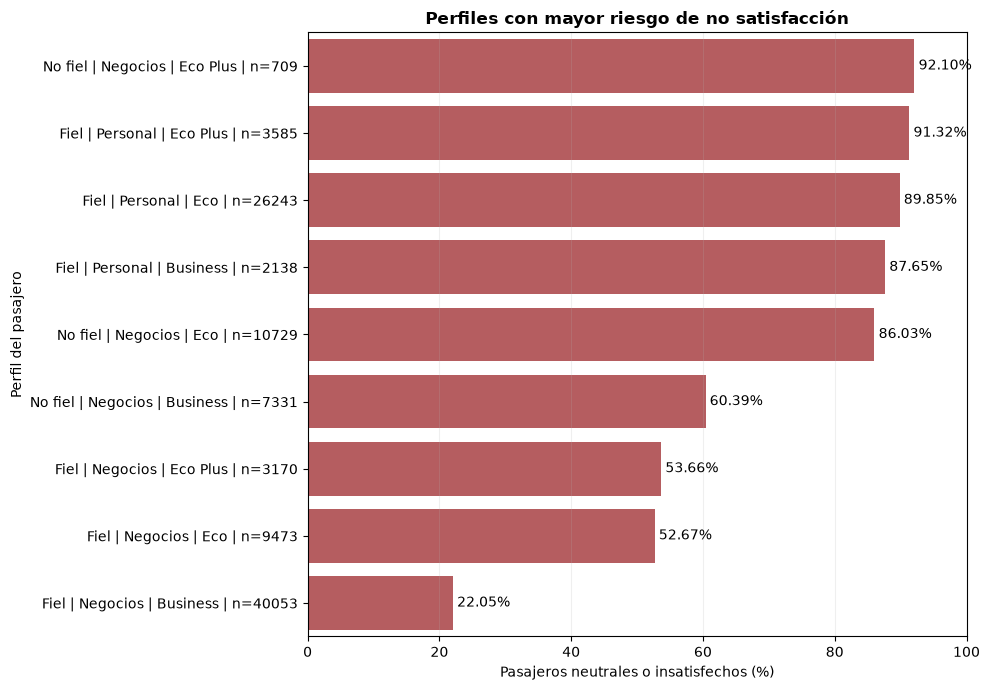

In [49]:
ranking_grafico = ranking_riesgo.copy()

nombres_cliente = {
    "disloyal customer": "No fiel",
    "loyal customer": "Fiel"
}

nombres_viaje = {
    "business travel": "Negocios",
    "personal travel": "Personal"
}

nombres_clase = {
    "business": "Business",
    "eco": "Eco",
    "eco plus": "Eco Plus"
}

ranking_grafico["perfil"] = (
    ranking_grafico["customer_type"].replace(nombres_cliente)
    + " | "
    + ranking_grafico["type_of_travel"].replace(nombres_viaje)
    + " | "
    + ranking_grafico["class"].replace(nombres_clase)
    + " | n="
    + ranking_grafico["cantidad_pasajeros"].astype(str)
)

plt.figure(figsize=(10, 7))

ax = sns.barplot(
    data=ranking_grafico,
    x="porcentaje_no_satisfechos",
    y="perfil",
    color="#C44E52"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.2f%%",
    padding=3
)

ax.set_title(
    "Perfiles con mayor riesgo de no satisfacción",
    fontweight="bold"
)

ax.set_xlabel("Pasajeros neutrales o insatisfechos (%)")
ax.set_ylabel("Perfil del pasajero")
ax.set_xlim(0, 100)

plt.grid(axis="x", alpha=0.20)
plt.tight_layout()
plt.show()

# Conclusiones generales

El análisis muestra que la aerolínea presenta una oportunidad importante de mejora: solamente el 43,34 % de los pasajeros se declara satisfecho, mientras que el 56,66 % restante aparece como neutral o insatisfecho.

La clase, el motivo del viaje y la fidelidad del cliente están fuertemente asociados con la satisfacción. Business alcanza un 69,43 % de pasajeros satisfechos, frente al 18,61 % de Eco y el 24,58 % de Eco Plus. Los viajes de negocios también presentan mayor satisfacción que los personales: 58,26 % frente a 10,16 %.

Sin embargo, estas variables están relacionadas entre sí. El 66,30 % de los pasajeros que viajan por negocios utiliza Business, mientras que el 82,14 % de los viajes personales se realiza en Eco. Aun controlando la clase, los pasajeros de negocios continúan mostrando mayor satisfacción, por lo que tanto la clase como el motivo del viaje parecen estar relacionados con la experiencia.

Los clientes fieles alcanzan una satisfacción del 47,73 %, frente al 23,68 % de los no fieles. Esto muestra una asociación entre fidelidad y satisfacción, aunque el análisis no permite determinar si la fidelidad genera mejores experiencias o si las buenas experiencias favorecen la fidelización.

Entre los servicios evaluados, los factores más relacionados con la satisfacción son el embarque online (0,50), el entretenimiento a bordo (0,40) y la comodidad del asiento (0,35). Al considerar también el costo y la viabilidad, la aerolínea podría priorizar mejoras en el proceso digital, el entretenimiento y la atención al pasajero.

Los retrasos también están asociados con una menor satisfacción. Los pasajeros sin retraso alcanzan un 47,28 % de satisfacción, mientras que en demoras superiores a 60 minutos el porcentaje disminuye al 35,72 %. La caída principal ocurre al superar los primeros 15 minutos y luego se estabiliza alrededor del 35 %.

El perfil con mayor porcentaje de no satisfacción entre los grupos con al menos 500 registros es el cliente no fiel que viaja por negocios en Eco Plus, con un 92,10 %. Sin embargo, el segmento fiel que realiza viajes personales en Eco constituye una oportunidad comercial más amplia: presenta un 89,85 % de no satisfacción y reúne a 26.243 pasajeros.

## Recomendaciones

1. Optimizar el embarque online y reducir errores o pasos innecesarios.
2. Mejorar el entretenimiento y la atención durante el vuelo.
3. Investigar las causas de la baja satisfacción en los viajes personales.
4. Evitar que los retrasos superen los 15 minutos cuando sea posible.
5. Mejorar la comunicación y asistencia durante las demoras inevitables.
6. Diseñar acciones específicas para los segmentos de alto riesgo, priorizando también aquellos con mayor volumen de pasajeros.

## Limitaciones

Los resultados muestran asociaciones y no permiten demostrar causalidad. Además, la categoría “neutral or dissatisfied” combina dos respuestas diferentes. Las recomendaciones deberían validarse mediante análisis adicionales, pruebas controladas y, posteriormente, un modelo predictivo.